# 2.1 Differential expression analysis
## 2.1 遺伝子発現変動解析
Updated 2026-06-23  
更新日 2026-06-23  

> この文書の日本語訳は AI（Claude Opus 4.8）によって作成されました。正式な原文は英語版です。誤りや不自然な表現に気づいた場合は、英語版を参照してください。

Data are mouse brain, *Atp8a1* single-knockout (KO) vs *Atp8a1/2* double-knockout (DKO), sampled at two developmental timepoints: P0 (day of birth) and P14 (two weeks later). 5 biological replicates per genotype per timepoint (total 20 samples).  
データはマウスの脳で、*Atp8a1* 単独ノックアウト（KO）と *Atp8a1/2* 二重ノックアウト（DKO）を、2つの発生時点（P0：出生当日、P14：2週間後）で採取したものです。遺伝子型・時点ごとに生物学的反復が5つずつ（合計20サンプル）あります。

For more information, see the **[DESeq2 docs](https://bioconductor.org/packages/devel/bioc/vignettes/DESeq2/inst/doc/DESeq2.html)**.  
詳細は **[DESeq2 ドキュメント](https://bioconductor.org/packages/devel/bioc/vignettes/DESeq2/inst/doc/DESeq2.html)** を参照してください。

This notebook works through the following analysis:  
このノートブックでは、次の解析を順に進めます。

2.1.1. **PCA** of all samples, to look for structure, outliers, and the dominant sources of variation;  
       全サンプルの **PCA**。構造、外れ値、そして分散の主な要因を調べる；  
2.1.2. **Pairwise** KO-vs-DKO comparisons, run separately within each timepoint (P0, then P14);  
       各時点（P0、続いて P14）ごとに別々に行う、KO 対 DKO の **ペアワイズ** 比較；  
2.1.3. A **multifactorial** model using all samples at once, including a test for a genotype × timepoint *interaction*,  asking whether effect of the knockout depends on developmental stage;  
       全サンプルを一度に使う **多因子** モデル。遺伝子型 × 時点の *交互作用* の検定を含み、ノックアウトの効果が発生段階に依存するかを問う；  
2.1.4. Plotting differential genes using a **volcano plot**.  
       **ボルケーノプロット** を使って発現変動遺伝子を可視化する。

## Dependencies
### 依存パッケージ
Dependencies are listed in `differential-expression.yml`. Install with `conda` or using the included `install.sh` script.  
依存パッケージは `differential-expression.yml` に記載されています。`conda` を使うか、付属の `install.sh` スクリプトを使ってインストールしてください。

## Required input files
### 必要な入力ファイル
Put these files in the `data` directory.  
これらのファイルを `data` ディレクトリに置いてください。

**atp8a2.expected_counts.tsv**: expected transcript counts from `RSEM`, gene × sample. Row names are of the form `ENSMUSG00000000001_Gnai3`. Data are not yet published; ask Owen for the download link. **Do not redistribute**.  
**atp8a2.expected_counts.tsv**：`RSEM` による expected transcript counts（遺伝子 × サンプル）。行名は `ENSMUSG00000000001_Gnai3` の形式です。データは未発表です。ダウンロードリンクは Owen に問い合わせてください。**再配布しないでください**。

**sample_metadata.tsv**: sample annotations `treatment` (KO/DKO), `timepoint` (P0/P14). Included in this repo.  
**sample_metadata.tsv**：サンプルの注釈 `treatment`（KO/DKO）、`timepoint`（P0/P14）。このリポジトリに含まれています。

**Mus_musculus.GRCm39.113.gtf**: Ensembl gene annotation (release 113, GRCm39). Download from https://ftp.ensembl.org/pub/release-113/gtf/mus_musculus/Mus_musculus.GRCm39.113.gtf.gz.  
**Mus_musculus.GRCm39.113.gtf**：Ensembl の遺伝子アノテーション（release 113、GRCm39）。https://ftp.ensembl.org/pub/release-113/gtf/mus_musculus/Mus_musculus.GRCm39.113.gtf.gz からダウンロードしてください。

In [1]:
# Load dependencies

Sys.setenv(LANGUAGE = "en") # set language to "ja" if you prefer
library(DESeq2)             # differential expression
library(plyranges)          # genomic regions
library(tidyverse)          # tables
library(ggplot2)            # plotting
library(ggrepel)            # pretty labels on plots
library(extrafont)          # Use Arial font
library(svglite)            # save .svg files
library(patchwork)          # combine plots
library(dplyr)

getwd()                     # print the working directory
sessionInfo()               # print all library versions

Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, which.max, which.min



Attaching package: ‘S4Vectors’


The following object is masked from ‘package:utils’:

    findMatches


The follo

[1] "/Users/ziyao/Documents/ups/analysis/rnaseq/code"

R version 4.5.3 (2026-03-11)
Platform: x86_64-apple-darwin13.4.0
Running under: macOS Tahoe 26.6.2

Matrix products: default
BLAS:   /Users/ziyao/miniforge3/envs/heatmap/lib/libopenblasp-r0.3.34.dylib 
LAPACK: /Users/ziyao/miniforge3/envs/differential-expression/lib/libopenblasp-r0.3.33.dylib;  LAPACK version 3.12.0

locale:
[1] C.UTF-8/UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8

time zone: Asia/Tokyo
tzcode source: system (macOS)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] patchwork_1.3.2             svglite_2.2.2              
 [3] extrafont_0.20              ggrepel_0.9.8              
 [5] lubridate_1.9.5             forcats_1.0.1              
 [7] stringr_1.6.0               purrr_1.2.2                
 [9] readr_2.2.0                 tidyr_1.3.2                
[11] tibble_3.3.1                ggplot2_4.0.3              
[13] tidyverse_2.0.0             plyranges_1.30.1           
[15] dplyr

In [2]:
# Plotting defaults
suppressMessages(extrafont::font_import(pattern="Arial",prompt=FALSE))
suppressMessages(extrafont::loadfonts())

base_theme <- theme_classic(base_size=14, base_family="Arial",) +
    theme(axis.text = element_text(size=14,colour="black"),
          aspect.ratio=1,
         )
theme_set(base_theme)

write_plot <- function(plt,outfile,width,height){
    b=basename(outfile)
    d=dirname(outfile)
    dir.create(d, recursive=TRUE, showWarnings = FALSE)
    pdf.options(encoding='ISOLatin2.enc')
    pngName = paste(b, ".png", sep="")
    svgName = paste(b, ".svg", sep = "")
    ggsave(path=d, device="png", filename=pngName, width=width, height=height, units='in')
    ggsave(path=d, device="svg", filename=svgName, width=width, height=height, units='in')
}

# 2.1.0 Get and process data
## 2.1.0 データの取得と前処理

In [3]:
data_location = '~/Documents/ups/data/rnaseq/rsem/rsem.merged.gene_counts.tsv'
annotation_location = '~/Documents/anno/Homo_sapiens.GRCh38.113.gtf'
metadata_location = '~/Documents/ups/data/methylation/methyl_classifications.tsv'

In [4]:
# Read and preprocess expression data

load_annotations <- function(annotation_path) {
    # Load gene annotations from a .gtf file.
    g <- rtracklayer::import(annotation_path) %>%
        filter(type=='gene') %>%
        filter(gene_biotype=='protein_coding')
    return(g)
}

filter_protein_coding <- function(gene_matrix,annotation_path){
    # given a matrix with rownames of the form ENSMUSG00000000001_Gnai3,
    # return a subset consisting of only rows where the stable gene ID ENSMUSG00000000001
    # is annotated as a protein-coding gene.
    message('filtering for protein-coding genes ...')
    g <- load_annotations(annotation_path)
    # rsem.merged.gene_counts.tsv uses stable ENSMUSG IDs
    ensembl_ids <- sub("_.*", "", rownames(gene_matrix))
    keep <- ensembl_ids %in% g$gene_id
    filtered_data <- gene_matrix[keep, ]
    return(filtered_data)
}

load_gex  <- function(data_location,annotation_location){
    message("loading gene expression data from ", data_location, "...")
    cts = read.csv(data_location, sep="\t", row.names="gene_id", check.names=FALSE)
    cts$gene_name = NULL
    cts = as.matrix(cts)
    cts = round(cts) # counts must be integer
    cts = filter_protein_coding(cts,annotation_location)
    # new_rownames <- sub("^ENSMUSG\\d*_", "", rownames(cts))
# rownames(cts) <- new_rownames
    return(cts)
}

load_metadata <- function(metadata_location,sample_set = NULL){
    annot = read.table(metadata_location, check.names=FALSE,row.names=1,header=TRUE)
    rownames(annot) <- gsub("_.*$", "", rownames(annot)) # drop suffixes
    if (!is.null(sample_set)){
        annot = annot[rownames(annot) %in% sample_set, ]
        annot[setdiff(sample_set,rownames(annot)), ] = NA
        annot = annot[sample_set, ]
    }
    return(annot)
}

data = load_gex(data_location,annotation_location)
dim(data) # # of genes and samples
data %>% head # first 5 rows

loading gene expression data from ~/Documents/ups/data/rnaseq/rsem/rsem.merged.gene_counts.tsv...

filtering for protein-coding genes ...



[1] 20116    31

,PDXSAR008,PDXSAR010,PDXSAR023,PDXSAR028,SAR005,SAR007,SAR008,SAR009,SAR010,SAR015,⋯,SAR055,SAR057,SAR058,SAR061,SAR066,SAR074,SAR083,SAR084,SAR085,SAR086
ENSG00000000003,346,53,1019,601,99,30,131,94,631,110,⋯,103,131,392,130,113,217,131,115,492,189
ENSG00000000005,0,0,360,0,0,0,0,0,4,1,⋯,0,1,0,3,3,1,0,0,5,0
ENSG00000000419,86,100,65,96,15,21,62,50,109,55,⋯,72,94,97,60,27,70,24,43,69,50
ENSG00000000457,133,105,110,126,52,40,72,87,179,52,⋯,53,78,40,45,46,45,55,38,47,49
ENSG00000000460,244,198,222,123,39,23,144,24,215,50,⋯,48,199,51,56,23,58,53,18,22,44
ENSG00000000938,1,427,0,5,84,29,7,76,6,20,⋯,0,13,33,12,16,21,17,28,15,4


In [5]:
# Read methylation classes as annotations
annot <- load_metadata(metadata_location, colnames(data))
annot

,class,subclass
,<chr>,<chr>
PDXSAR008,UPS/MFS/LS_PL/RMS_PL,NC
PDXSAR010,HS,HS_A
PDXSAR023,MPNST,MPNST
PDXSAR028,UPS/MFS/LS_PL/RMS_PL,NC
SAR005,NC,NC
SAR007,NC,NC
SAR008,UPS/MFS/LS_PL/RMS_PL,NC
SAR009,CTRL_BONE,CTRL_BONE
SAR010,UPS/MFS/LS_PL/RMS_PL,MFS


# 2.1.1 Principal components analysis (PCA) on all samples
## 2.1.1 全サンプルに対する主成分分析（PCA）

## Purpose
### 目的
Do samples cluster by genotype (KO vs DKO) or by timepoint (P0 vs P14) in the first two PCs?  
最初の2つの主成分で、サンプルは遺伝子型（KO 対 DKO）や時点（P0 対 P14）ごとにまとまるか？  
Are any samples outliers?  
外れ値となるサンプルはあるか？  
Which factor explains the most variance?  
最も分散を説明する要因はどれか？

## Results
### 結果
PC1 (93% of variance) separates P0 and P14.  
PC1（分散の93%）が P0 と P14 を分離する。

## Outputs
### 出力
`results/atp8a2/pca_all.{png,svg}`

In [6]:
dds <- DESeq2::DESeqDataSetFromMatrix(countData = data,
                              colData = annot,
                              design = ~ 1)
# Pre-filter. Note more generous cutoffs since we have more samples.
smallestGroupSize <- 6
keep <- rowSums(counts(dds) >= 10) >= smallestGroupSize
dds <- dds[keep,]
# Run regression
dds <- DESeq(dds)
dds

converting counts to integer mode

Warning message in DESeq(dds):
“the design is ~ 1 (just an intercept). is this intended?”
estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 845 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



class: DESeqDataSet 
dim: 13742 31 
metadata(1): version
assays(6): counts mu ... replaceCounts replaceCooks
rownames(13742): ENSG00000000003 ENSG00000000419 ... ENSG00000293642
  ENSG00000310517
rowData names(19): baseMean baseVar ... maxCooks replace
colnames(31): PDXSAR008 PDXSAR010 ... SAR085 SAR086
colData names(4): class subclass sizeFactor replaceable

In [7]:
# print matrix size after pre-filtering
dim(counts(dds))

[1] 13742    31

In [8]:
# Fixed colors for methylation classes
pca_colors <- c(
    "CTRL_BONE" = "#F8766D",
    "CTRL_MUS" = "#C49A00",
    "HS" = "#53B400",
    "MPNST" = "#00C094",
    "NC" = "#00B6EB",
    "UPS/MFS/LS_PL/RMS_PL" = "#A58AFF",
    "UPS/MFS/LS_PL/RMS_PL?" = "#FB61D7"
)

using ntop=500 top features by variance



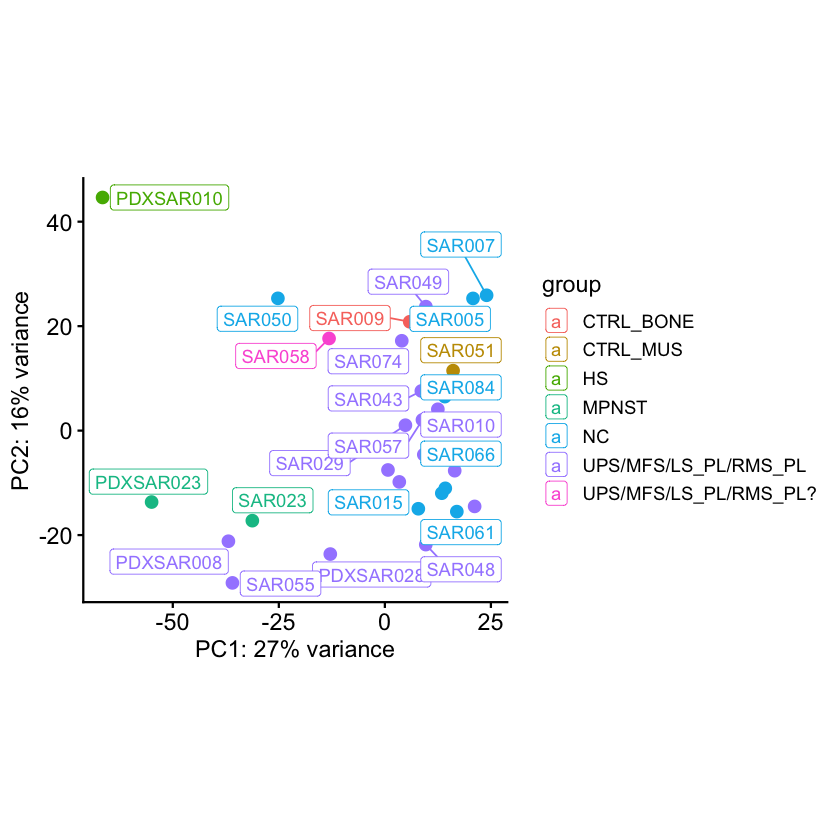

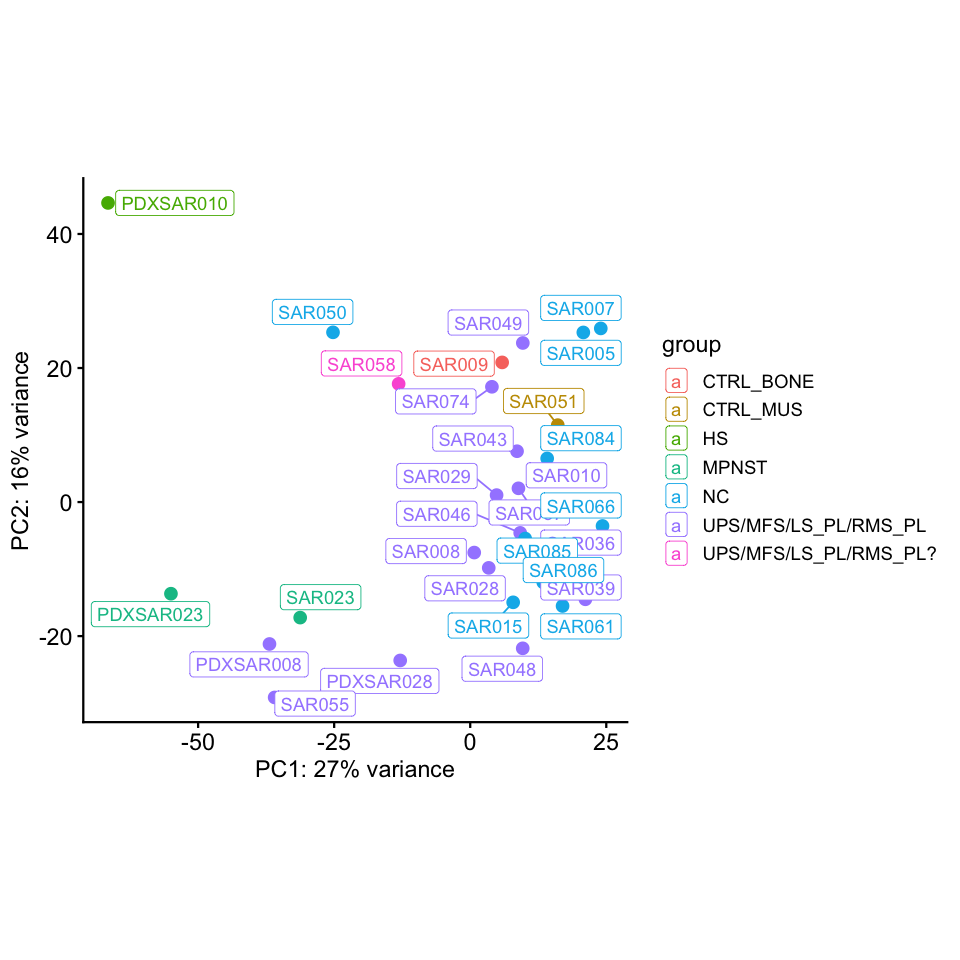

In [9]:
# PCA on all samples. Looks like substantial and nonlinear (at least wrt. the first 2 PCs) batch effect.
vsd <- vst(dds, blind=TRUE)

a <- plotPCA(vsd, intgroup = "class") +
    geom_label_repel(aes(label = name)) +
    scale_color_manual(values = pca_colors)

a

w=8;h=8
write_plot(a,outfile='results/deseq2/pca',width=w,height=h)
options(repr.plot.width=w, repr.plot.height=h)
a

In [10]:
dim(assay(vsd))

[1] 13742    31

In [11]:
assay(vsd)[1:5, 1:5]

,PDXSAR008,PDXSAR010,PDXSAR023,PDXSAR028,SAR005
ENSG00000000003,8.025615,5.832445,9.498434,8.560165,7.140022
ENSG00000000419,6.351198,6.474323,6.066935,6.307833,5.269230
ENSG00000000457,6.836565,6.527788,6.623934,6.602974,6.402510
ENSG00000000460,7.574963,7.268738,7.460356,6.576126,6.103607
ENSG00000000938,3.967691,8.255378,3.629474,4.325591,6.943721


In [12]:
write.table(
    assay(vsd),
    file = "/Users/ziyao/Documents/ups/data/ps_31sample.vst.tsv",
    sep = "\t",
    quote = FALSE,
    col.names = NA
)

In [ ]:
# PDXSAR010, PDXSAR023, SAR023, SAR050, SAR009 なしのPCA

using ntop=500 top features by variance



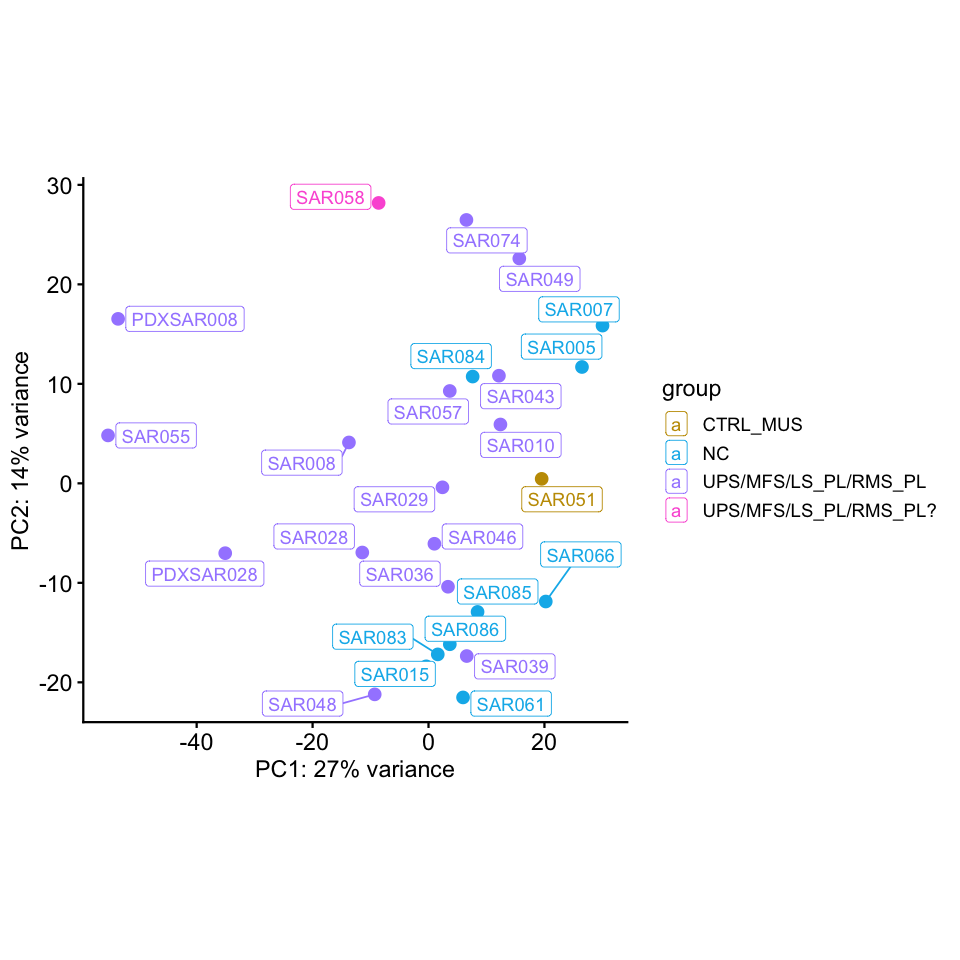

In [17]:
exclude_samples <- c(
    "PDXSAR010",
    "PDXSAR023",
    "SAR023",
    "SAR050",
    "SAR009"
)

dds_filtered <- dds[, !(colnames(dds) %in% exclude_samples)]

vsd_filtered <- vst(dds_filtered, blind = TRUE)

a_filtered <- plotPCA(
    vsd_filtered,
    intgroup = "class"
) +
    geom_label_repel(aes(label = name)) +
    scale_color_manual(values = pca_colors)

a_filtered

In [19]:
out <- "~/Documents/ups/analysis/rnaseq/results/PCA"
dir.create(out, recursive = TRUE, showWarnings = FALSE)

for (n in c("31", "26")) {
    p <- if (n == "31") a else a_filtered
    for (ext in c("png", "svg")) {
        ggsave(file.path(out, paste0("pca_", n, "samples.", ext)),
               plot = p, width = 8, height = 8, dpi = 300)
    }
}

In [ ]:
# write vst quantifications
file = "results/deseq2/ups.vst.tsv"
vsd %>% assay %>% write.table(
  file = file,
  sep = "\t",
  quote = FALSE,
  col.names = NA
)